## {Intro}

In [2]:
import pandas as pd

url = "http://byungwan.com/class/Coupon_Sample.xlsx"
coupon = pd.read_excel(url)
coupon.head()

,CID,Gender,Age,CClass,Discount,Visits,Email,SMS,MStatus,Purchases,Sales
0,1,0,41,2,0,1,0,1,1,1,0.92
1,2,0,41,1,0,0,0,0,0,0,0.00
2,3,0,30,2,0,3,0,0,0,1,1.54
3,4,0,28,2,0,2,0,0,0,2,0.88
4,5,1,24,2,1,5,0,0,0,2,0.53


## 1. Linear Regression W/ Non-linear terms

In [3]:
from statsmodels.formula import api as smf

In [12]:
reg = smf.ols(formula = "Sales ~ Gender + Age + CClass + Discount + Visits + Email + SMS + MStatus + Purchases", data = coupon).fit() #Generally, we include intercept but add -1 at the end of the formula if you want to remove intercept
print(reg.summary())

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.727
Model:                            OLS   Adj. R-squared:                  0.722
Method:                 Least Squares   F-statistic:                     144.8
Date:                Thu, 08 Oct 2026   Prob (F-statistic):          7.77e-132
Time:                        10:52:30   Log-Likelihood:                -340.75
No. Observations:                 499   AIC:                             701.5
Df Residuals:                     489   BIC:                             743.6
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.5064      0.126     -4.027      0.0

In [15]:
import numpy as np

In [16]:
reg2 = smf.ols(formula = "Sales ~ Gender + Age + CClass + Discount + Visits + Email + SMS + MStatus + Purchases + np.power(Purchases, 2)", data = coupon).fit() 
print(reg2.summary())

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.731
Model:                            OLS   Adj. R-squared:                  0.725
Method:                 Least Squares   F-statistic:                     132.5
Date:                Thu, 08 Oct 2026   Prob (F-statistic):          3.84e-132
Time:                        11:00:48   Log-Likelihood:                -337.44
No. Observations:                 499   AIC:                             696.9
Df Residuals:                     488   BIC:                             743.2
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                 -0

In [17]:
coupon["Purchases"].describe()

# max = 12.00
# check hypothesis through plotting manually

count    499.000000
mean       1.218437
std        1.399362
min        0.000000
25%        0.000000
50%        1.000000
75%        1.000000
max       12.000000
Name: Purchases, dtype: float64

In [19]:
x1 = np.array(range(0,13)) #range from min to max +1 because range does not include the last value
y1 = (-0.3970) + 0.5905 * x1 + (-0.0132) * (x1**2) #y = 𝛼 + 𝛽𝑥 + 𝛾𝑥^2 

# alpha = Intercept
# beta = purchases
# gamma = purchases**2

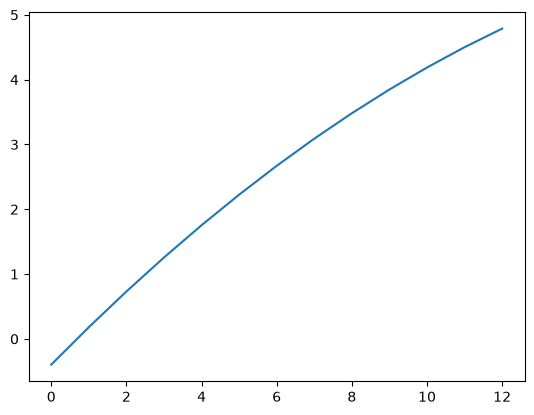

In [20]:
from matplotlib import pyplot as plt

plt.plot(x1, y1)
plt.show()

#hypothesis = False

In [24]:
reg3 = smf.ols(formula = "Sales ~ Gender + Age + np.power(Age, 2) + CClass + Discount + Visits + Email + SMS + MStatus + Purchases + np.power(Purchases, 2)", data = coupon).fit() 
print(reg3.summary())

# include squared term only if raw term (Age) is statistically significant (p-value < 0.05) or both raw term (Age) and sqaured term (Age, 2) is significant.
# otherwise, remove sqaured term

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.731
Model:                            OLS   Adj. R-squared:                  0.725
Method:                 Least Squares   F-statistic:                     120.5
Date:                Thu, 08 Oct 2026   Prob (F-statistic):          2.74e-131
Time:                        11:14:13   Log-Likelihood:                -336.92
No. Observations:                 499   AIC:                             697.8
Df Residuals:                     487   BIC:                             748.4
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                 -0

In [25]:
coupon["Age"].describe()

count    499.000000
mean      27.853707
std        7.346600
min       12.000000
25%       23.000000
50%       27.000000
75%       31.000000
max       56.000000
Name: Age, dtype: float64

In [26]:
x2 = np.array(range(12,57)) #range from min to max + 1
y2 = (-0.6611) + (0.0239)*x2 + (-0.0003)*(x2**2)

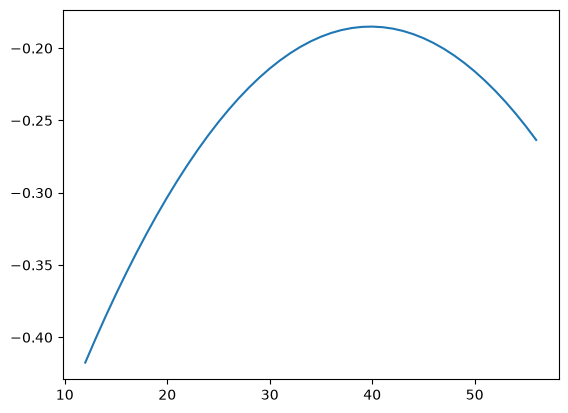

In [27]:
plt.plot(x2,y2)
plt.show()